In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

import cartopy.crs as ccrs
import seaborn as sns
import cmocean

In [2]:
from nese.dataprep.sources import CMEMSL3SLAARCO
from nese.verify.data import open_anemoi_dataset
from nese.verify.maps import set_region, draw_cells, REGIONS, projection

from importlib.resources import files
plt.style.use(files("nese.verify") / "nese.mplstyle")

In [3]:
def get_raw_data(date, mission, freq):
    source = CMEMSL3SLAARCO(
        time={"start": date, "end": date, "freq": freq},
        variables=["sla_filtered"],
        groups=[mission],
    )
    raw = source.open_record_dataset({"time": date})[mission]
    return raw

In [4]:
the_date = "2018-10-05T12"
raw_date = "2018-10-05"

In [5]:
raw = get_raw_data(
    date=raw_date,
    mission="jason_3",
    freq="24h",
)

INFO - 2026-10-16T07:03:05Z - Selected dataset version: "202411"
INFO - 2026-10-16T07:03:05Z - Selected dataset part: "default"


In [6]:
raw

<xarray.Dataset> Size: 2MB
Dimensions:       (obs: 47914)
Coordinates:
    time          (obs) datetime64[ns] 383kB 2018-10-05 ... 2018-10-05T23:46:40
    latitude      (obs) float64 383kB -57.76 -57.8 -57.84 ... 39.79 39.74 39.69
    longitude     (obs) float64 383kB 66.85 66.92 67.0 ... 1.016 1.051 1.085
Dimensions without coordinates: obs
Data variables:
    sla_filtered  (obs) float64 383kB 0.004 -0.008 -0.017 ... 0.197 0.197 0.195

In [7]:
ds6 = open_anemoi_dataset("anemoi-hpx6-24h/dataset.zarr")
ds8 = open_anemoi_dataset("anemoi-hpx8-24h/dataset.zarr")

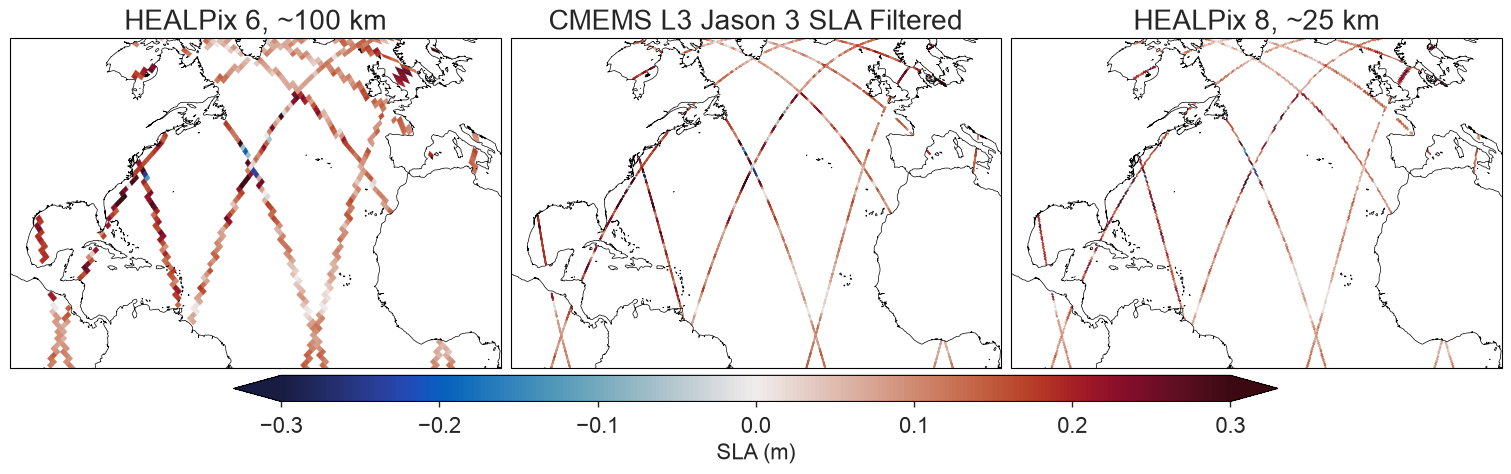

In [13]:
vmax = 0.3
fig, axs = plt.subplots(1, 3, figsize=(15, 7), subplot_kw={"projection": projection("north_atlantic")})
#fig, axs = plt.subplots(3, 1, figsize=(7, 4*3), subplot_kw={"projection": projection("north_atlantic")})

for xds, level, rez, ax in zip([ds6, ds8], [6, 8], [100, 25], [axs[0], axs[-1]]):
    set_region(ax, "north_atlantic", land="1.0")
    draw_cells(
        ax,
        xds["sla_filtered_jason_3"].sel(time=the_date, method="nearest"),
        attrs=xds.attrs,
        cmap="cmo.balance",
        vmax=vmax,
        vmin=-vmax,
    )
    ax.set(title=f"HEALPix {level}, ~{rez} km")

ax = axs[1]
set_region(ax, "north_atlantic", land="1.0")
mappable = ax.scatter(
    raw.longitude,
    raw.latitude,
    c=raw.sla_filtered,
    s=1,
    cmap="cmo.balance",
    vmax=vmax,
    vmin=-vmax,
    transform=ccrs.PlateCarree(),
)
ax.set(title="CMEMS L3 Jason 3 SLA Filtered")
#fig.colorbar(mappable, ax=axs, label="SLA (m)", shrink=0.7, extend="both", orientation="vertical", aspect=40)
fig.colorbar(mappable, ax=axs, label="SLA (m)", shrink=0.7, extend="both", orientation="horizontal", aspect=40, pad=.01)
fig.savefig("raw_and_binned.jpeg", dpi=300, bbox_inches="tight")